# Horvath (2013) Epigenetic Clock

This notebook demonstrates the `Horvath` clock class from `epigenetic_clocks.py`.

All the reusable, clock-agnostic logic (age transforms, the linear-combination
predictor, evaluation metrics, and validation against published benchmarks)
lives in `epigenetic_clocks.py` as plain functions, so it can be reused by
other clocks (Hannum, PhenoAge, Skin&Blood, ...). Everything specific to the
Horvath clock (the 353-CpG coefficient file format, `adult_age=20`, the
paper's exact metric column names/tolerances) is encapsulated in the
`Horvath` class.

Reference: Horvath S. (2013) *DNA methylation age of human tissues and cell
types.* Genome Biology, 14:R115. https://doi.org/10.1186/gb-2013-14-10-r115


In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

from epigenetic_clocks import Horvath

## 1. Load data and initialise the clock

In [2]:
# ── Load your real data ───────────────────────────────────────────────
with open('/work/gr-fe/bryan/EpiHydra/data/02_processed/GSE41037/methylation.pkl', 'rb') as file:
    data = pickle.load(file)

# Beta value matrix (rows = CpGs, columns = samples)
methylation = data['CpG']

# Chronological ages, indexed by sample ID (used later for evaluation)
chron_ages = data['meta'].set_index('ID')['age']

# ── Initialise the Horvath clock ────────────────────────────────────────
# Coefficients come from Horvath 2013 supplementary AdditionalFile3.csv
clock = Horvath(coefficients_path="/work/gr-fe/bryan/EpiHydra/data/03_final/Horvath/horvath.csv")
clock.coefficients.head()

Loaded 353 CpG coefficients + intercept.


,CpGmarker,CoefficientTraining,CoefficientTrainingShrunk,varByCpG,minByCpG,maxByCpG,medianByCpG,medianByCpGYoung,medianByCpGOld,Gene_ID,...,SourceVersion,TSS_Coordinate,Gene_Strand,Symbol,Synonym,Accession,GID,Annotation,Product,Marginal Age Relationship
0,(Intercept),0.695507,0.886920,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cg00075967,0.129337,0.108096,0.02600,0.0160,0.97,0.750,0.720,0.750,64220.0,...,36.1,72282245.0,-,STRA6,PP14296; FLJ12541;,NM_022369.2,GI:21314699,synonyms: PP14296; FLJ12541,stimulated by retinoic acid gene 6 homolog,positive
2,cg00374717,0.005018,NaN,0.01200,0.0031,1.00,0.890,0.870,0.900,22901.0,...,36.1,63815191.0,+,ARSG,KIAA1001;,NM_014960.2,GI:45430056,go_function: hydrolase activity; go_function: ...,Arylsulfatase G,positive
3,cg00864867,1.599764,1.863969,0.00087,0.0000,0.58,0.049,0.045,0.053,5074.0,...,36.1,78608921.0,-,PAWR,PAR4; Par-4;,NM_002583.2,GI:55769532,##############################################...,PRKC; apoptosis; WT1; regulator,positive
4,cg00945507,0.056852,NaN,0.01600,0.0000,0.96,0.240,0.230,0.250,23480.0,...,36.1,54794433.0,-,SEC61G,SSS1;,NM_014302.3,GI:60279263,##############################################...,Sec61 gamma subunit,positive


## 2. Predict DNAm age

In [3]:
results = clock.predict(methylation)
results

,DNAmAge
SampleID,
GSM1007129,32.351061
GSM1007130,31.564583
GSM1007131,20.298511
GSM1007132,30.948976
GSM1007133,25.364005
...,...
GSM1007844,62.588952
GSM1007845,67.149885
GSM1007846,75.051997


## 3. Compare to chronological age

In [4]:
comparison = results.join(chron_ages.rename("ChronAge"))
comparison["AgeAcceleration"] = comparison["DNAmAge"] - comparison["ChronAge"]
comparison

,DNAmAge,ChronAge,AgeAcceleration
SampleID,,,
GSM1007129,32.351061,34.0,-1.648939
GSM1007130,31.564583,31.0,0.564583
GSM1007131,20.298511,23.0,-2.701489
GSM1007132,30.948976,31.0,-0.051024
GSM1007133,25.364005,23.0,2.364005
...,...,...,...
GSM1007844,62.588952,60.0,2.588952
GSM1007845,67.149885,68.0,-0.850115
GSM1007846,75.051997,73.0,2.051997


In [5]:
metrics = clock.compute_metrics(
    comparison["ChronAge"],
    comparison["DNAmAge"],
    age_accel_method="difference",
)
metrics

,"Cor(Age, m.age(Train.CpGs))","Median error (Age, m.age(Train.CpGs))",Median AgeAcceleration(Train.CpGs)
0,0.9526,2.7605,0.3109


## 4. Visualise

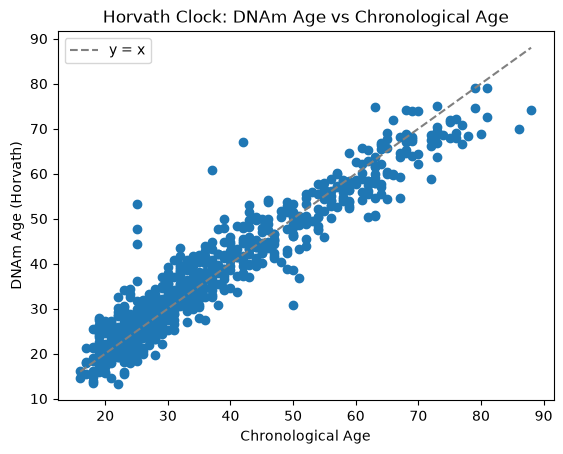

In [6]:
plt.scatter(comparison["ChronAge"], comparison["DNAmAge"])
plt.xlabel("Chronological Age")
plt.ylabel("DNAm Age (Horvath)")
plt.plot(
    [comparison["ChronAge"].min(), comparison["ChronAge"].max()],
    [comparison["ChronAge"].min(), comparison["ChronAge"].max()],
    linestyle="--", color="grey", label="y = x",
)
plt.legend()
plt.title("Horvath Clock: DNAm Age vs Chronological Age")
plt.show()

## 5. Validate against published (paper) results

Compare the metrics computed above against the values published for this
dataset in Horvath (2013)'s supplementary tables.

In [7]:
paper_results = pd.read_csv(
    '/work/gr-fe/bryan/EpiHydra/data/03_final/Horvath/horvath_results.csv',
    encoding='latin-1',
)
paper_results

,Data label (color),DNA origin,Platform,Data Use,n (Prop.Female),Median Age(range),Citation,Availability,"Cor(Age,m.age(Train.CpGs))","Median error (Age, m.age(Train.CpGs))",Median AgeAcceleration(Train.CpGs),Cor LOOCV,Error LOOCV
0,1 (turquoise),Blood WB,27K,Training,715 (0.38),"33 (16,88)",Horvath 2012,GSE41037,0.96,2.8,-0.1,0.95 (0),3.2
1,2 (blue),Blood WB,450K,Training,94 (0.28),"29 (18,65)",Horvath 2012,GSE41169,0.93,2.5,0.7,0.92 (0),2.7
2,3 (brown),Blood WB,450K,Training,656 (0.52),"65 (19,100)",Hannum 2012,GSE40279,0.91,3.9,-0.7,0.88 (0),8.9
3,4 (blue2),Blood PBMC,450K,Training,72 (0),"3.1 (1,16)",Alisch 2012,GSE36064,0.96,0.5,0.3,0.96 (0),0.8
4,5 (green),Blood PBMC,450K,Training,48 (0.52),"15 (3.5,76)",Harris et al 2012,GSE32149,0.96,2.4,-0.5,0.95 (0),1.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
77,78,Stem cells+Somatic Cells,450K,Other,153 (0.63),NaN,Nazor 2012,GSE31848,NaN,NaN,NaN,NaN,NaN
78,79,Reprogrammed mesenchymal stromal cells,450K,Other,24 (NA),NaN,Shao 2012,GSE37066,NaN,NaN,NaN,NaN,NaN
79,80,HematopoieticStemAndNormalPrimaryTissue,27k,Other,34 (NA),NaN,Calvanese 2012,GSE30090,NaN,NaN,NaN,NaN,NaN
80,81,hESC,27k,Other,6 (NA),NaN,Ramos-Mejía 2012,GSE30456,NaN,NaN,NaN,NaN,NaN


In [8]:
validation = clock.validate(
    metrics,
    paper_results[paper_results['Availability'] == 'GSE41037'],
    dataset_name="GSE41037",
)
validation


  Clock Validation — GSE41037
                          Yours  Paper  Abs. Diff  Tolerance  Status
Metric                                                              
Cor(Age, DNAmAge)        0.9526   0.96     0.0074        0.1  ✓ Pass
Median Error             2.7605   2.80     0.0395        0.5  ✓ Pass
Median Age Acceleration  0.3109  -0.10     0.4109        0.5  ✓ Pass
  ✓ All metrics within tolerance.
  Implementation appears correct.



,Yours,Paper,Abs. Diff,Tolerance,Status
Metric,,,,,
"Cor(Age, DNAmAge)",0.9526,0.96,0.0074,0.1,✓ Pass
Median Error,2.7605,2.80,0.0395,0.5,✓ Pass
Median Age Acceleration,0.3109,-0.10,0.4109,0.5,✓ Pass


## 6. (Optional) One-shot pipeline

`Horvath.run()` bundles prediction + comparison + metrics into a single call,
useful once you trust the individual steps above.

In [9]:
out = clock.run(methylation, chron_ages=chron_ages, age_accel_method="difference")
out["metrics"]

,"Cor(Age, m.age(Train.CpGs))","Median error (Age, m.age(Train.CpGs))",Median AgeAcceleration(Train.CpGs)
0,0.9526,2.7605,0.3109
